# Analyse exploratoire

Première analyse exploratoire des données, pour orienter la préparation (valeurs manquantes,
normalisation, agrégation des statistiques individuelles, variables dérivées, momentum,
réduction de dimension). Deux sources, quatre types de données chacune :

| | NHL (MySQL) | MoneyPuck (CSV) |
|---|---|---|
| Matchs | `games` | reconstruits depuis `all_teams.csv` |
| Équipes | `t_summary`, `t_realtime`, `t_percentages` | `teams/all_teams.csv` |
| Patineurs | `summary` + `timeonice` | `skaters/*.csv` |
| Gardiens | `g_summary` | `goalies/*.csv` |

Pour chaque table : volume, couverture par saison, valeurs manquantes, distributions des
principales variables et corrélations. Périmètre : saisons **2005-2006 et suivantes** pour la
NHL ; MoneyPuck commence en 2008-2009. La saison est notée par son **année de début**
(`2005` = 2005-2006), comme chez MoneyPuck. On se limite à la saison régulière.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import text

from nhl_forecast.config import PROJECT_ROOT
from nhl_forecast.data.db.mysql import make_engine
from nhl_forecast.data.nhl_collect import stats_table
from nhl_forecast.data.sources.nhl_api import REPORTS

In [2]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#52514e"
sns.set_theme(style="whitegrid", palette=[BLEU, ORANGE])
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": "#e5e4e0",
    }
)

engine = make_engine()
MP_DIR = PROJECT_ROOT / "data" / "raw" / "moneypuck"
FIRST_GAME_ID = 2005_00_0000  # premier gameId de la saison 2005-2006


def sql(query, **params):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn, params=params)


def ajouter_saison(df, col="gameId"):
    """Saison (année de début) et type de match déduits du gameId (ex. 2005020001)."""
    gid = df[col].astype("int64")
    return df.assign(saison=gid // 1_000_000, type=((gid // 10_000) % 100).map({2: "R", 3: "P"}))


def manquants(df):
    """Colonnes ayant au moins une valeur manquante : nombre et proportion."""
    n = df.isna().sum()
    out = pd.DataFrame({"manquants": n, "proportion": n / len(df)})
    return out[out["manquants"] > 0].sort_values("proportion", ascending=False)


def manquants_par_saison(df, cols=None):
    """Proportion de valeurs manquantes par saison (colonnes ayant des manquants)."""
    cols = cols or [c for c in df.columns if df[c].isna().any() and c != "saison"]
    return df.groupby("saison")[cols].agg(lambda s: s.isna().mean())


def histos(df, cols, bins=40, ncols=4, hue=None):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.6 * nrows), squeeze=False)
    for ax, c in zip(axes.flat, cols, strict=False):
        # comptes entiers : une barre par valeur (évite les artefacts de regroupement)
        discret = pd.api.types.is_integer_dtype(df[c]) and df[c].nunique() <= 60
        largeur = {"discrete": True} if discret else {"bins": bins}
        sns.histplot(
            df,
            x=c,
            hue=hue,
            ax=ax,
            element="step",
            stat="density",
            common_norm=False,
            legend=ax is axes.flat[0] and hue is not None,
            **largeur,
        )
        ax.set_ylabel("")
    for ax in axes.flat[len(cols) :]:
        ax.set_visible(False)
    fig.tight_layout()


def heatmap_corr(df, cols, title, method="spearman"):
    corr = df[cols].corr(method=method)
    fig, ax = plt.subplots(figsize=(0.55 * len(cols) + 2, 0.45 * len(cols) + 1))
    sns.heatmap(
        corr,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        center=0,
        annot=len(cols) <= 16,
        fmt=".2f",
        annot_kws={"size": 7},
        square=True,
        cbar_kws={"shrink": 0.6},
        ax=ax,
    )
    ax.set_title(f"{title} (corrélation de {method.capitalize()})")
    return corr


def paires_correlees(corr, seuil=0.9):
    """Paires de variables très corrélées (|r| >= seuil) : redondance à surveiller (ACP/PLS)."""
    haut = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).rename_axis(index="var_1")
    tri = haut.reset_index().melt(id_vars="var_1", var_name="var_2", value_name="r").dropna()
    return tri[tri["r"].abs() >= seuil].sort_values("r", key=abs, ascending=False)

## 1. NHL (base de données)

### 1.1 Matchs — table `games`

Variable cible : victoire de l'équipe locale (saison régulière).
La saison en cours (2026-2027) n'a que quelques matchs. On vérifie les doublons, les scores manquants, le
nombre de matchs par saison, l'avantage de la glace et la répartition des fins de match
(`REG`, `OT`, `SO`).

In [3]:
games = sql(
    """
    SELECT game_id, season_id, game_type, date, home, away, score_home, score_away,
           end_game_type
    FROM games
    WHERE league = 'nhl' AND status = 'OFF' AND game_type = 'R'
      AND season_id REGEXP '^[0-9]{8}$' AND season_id >= '20052006'
    """
)
games["gameId"] = games["game_id"].astype("int64")
games = ajouter_saison(games)
games["home_win"] = (games["score_home"] > games["score_away"]).astype(int)
games["ecart"] = games["score_home"] - games["score_away"]
games["buts_total"] = games["score_home"] + games["score_away"]

print(f"{len(games):,} matchs terminés, saisons {games['saison'].min()}-{games['saison'].max()}")
print(f"doublons de gameId : {games['gameId'].duplicated().sum()}")
print(f"matchs nuls (score égal) : {(games['ecart'] == 0).sum()}")
manquants(games)

25,409 matchs terminés, saisons 2005-2026
doublons de gameId : 0
matchs nuls (score égal) : 0


,manquants,proportion


In [4]:
par_saison = games.groupby("saison").agg(
    matchs=("gameId", "size"),
    victoire_locale=("home_win", "mean"),
    buts_par_match=("buts_total", "mean"),
    prolongation=("end_game_type", lambda s: (s == "OT").mean()),
    fusillade=("end_game_type", lambda s: (s == "SO").mean()),
)
par_saison.style.format("{:.3f}").format("{:,.0f}", subset=["matchs"])

,matchs,victoire_locale,buts_par_match,prolongation,fusillade
saison,,,,,
2005,"1,230",0.574,6.169,0.111,0.118
2006,"1,230",0.550,5.891,0.095,0.133
2007,"1,230",0.537,5.567,0.094,0.127
2008,"1,230",0.559,5.825,0.100,0.129
2009,"1,230",0.561,5.680,0.095,0.150
2010,"1,230",0.519,5.585,0.120,0.121
2011,"1,230",0.559,5.468,0.097,0.147
2012,720,0.568,5.443,0.090,0.135
2013,"1,230",0.537,5.489,0.105,0.145


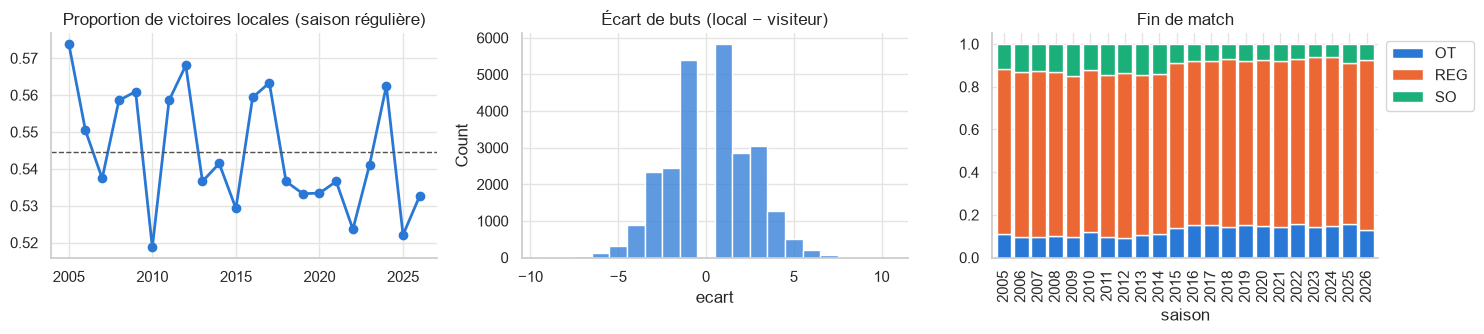

In [5]:
reg = games
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
s = reg.groupby("saison")["home_win"].mean()
axes[0].plot(s.index, s.values, marker="o", color=BLEU, lw=2)
axes[0].axhline(reg["home_win"].mean(), color=GRIS, ls="--", lw=1)
axes[0].set_title("Proportion de victoires locales (saison régulière)")
sns.histplot(reg["ecart"], discrete=True, ax=axes[1], color=BLEU)
axes[1].set_title("Écart de buts (local − visiteur)")
fin = pd.crosstab(reg["saison"], reg["end_game_type"], normalize="index")
fin.plot.bar(stacked=True, ax=axes[2], width=0.85, color=[BLEU, ORANGE, "#1baf7a"])
axes[2].set_title("Fin de match")
axes[2].legend(title="", loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()

In [6]:
# Équilibre des équipes : nombre de matchs locaux / visiteurs par équipe et saison
n_matchs = pd.concat(
    [
        reg[["saison", "home"]].rename(columns={"home": "team"}),
        reg[["saison", "away"]].rename(columns={"away": "team"}),
    ],
    ignore_index=True,  # crosstab exige un index sans doublons (pandas >= 3)
)
n_matchs = pd.crosstab(n_matchs["team"], n_matchs["saison"]).replace(0, np.nan)
n_matchs.describe().T[["count", "min", "50%", "max"]].rename(columns={"count": "équipes"})

,équipes,min,50%,max
saison,,,,
2005,30.000,82.000,82.000,82.000
2006,30.000,82.000,82.000,82.000
2007,30.000,82.000,82.000,82.000
2008,30.000,82.000,82.000,82.000
2009,30.000,82.000,82.000,82.000
2010,30.000,82.000,82.000,82.000
2011,30.000,82.000,82.000,82.000
2012,30.000,48.000,48.000,48.000
2013,30.000,82.000,82.000,82.000


### 1.2 Couverture des rapports statistiques

Pour chaque rapport, proportion des matchs de `games` présents dans la table, par saison. Une
couverture inférieure à 1 signale des matchs manquants (valeurs manquantes « structurelles » à
traiter à l'étape de préparation), différentes des cellules `NULL` à l'intérieur d'une table.

In [7]:
couverture = {}
for entity, reports in REPORTS.items():
    for report in reports:
        table = stats_table(entity, report)
        df = sql(
            f"""
            SELECT gameId DIV 1000000 AS saison, COUNT(DISTINCT gameId) AS matchs
            FROM `{table}` WHERE gameId >= :first GROUP BY saison
            """,
            first=FIRST_GAME_ID,
        )
        couverture[(entity, table)] = df.set_index("saison")["matchs"]

couverture = pd.DataFrame(couverture).T
couverture = couverture.div(games.groupby("saison").size(), axis=1)
couverture.style.format("{:.2f}", na_rep="—").background_gradient(cmap="Blues", vmin=0, vmax=1)

### 1.3 Statistiques d'équipes — `t_summary`, `t_realtime`, `t_percentages`

Une ligne par équipe-match. On joint trois rapports représentatifs : résultats et unités
spéciales (`summary`), jeu physique et revirements (`realtime`), possession et efficacité à
5 c. 5 (`percentages`).

In [8]:
teams = sql(
    """
    SELECT s.gameId, s.teamId, s.homeRoad, s.goalsFor, s.goalsAgainst,
           s.shotsForPerGame AS shotsFor, s.shotsAgainstPerGame AS shotsAgainst,
           s.powerPlayPct, s.penaltyKillPct, s.faceoffWinPct,
           r.hits, r.blockedShots, r.giveaways, r.takeaways, r.missedShots,
           p.satPct, p.usatPct, p.satPctClose, p.shootingPct5v5, p.savePct5v5, p.zoneStartPct5v5
    FROM t_summary s
    LEFT JOIN t_realtime r ON r.gameId = s.gameId AND r.teamId = s.teamId
    LEFT JOIN t_percentages p ON p.gameId = s.gameId AND p.teamId = s.teamId
    WHERE s.gameId >= :first
    """,
    first=FIRST_GAME_ID,
)
teams = ajouter_saison(teams)
print(f"{len(teams):,} lignes équipe-match, {teams['gameId'].nunique():,} matchs")
print("lignes par match :", teams.groupby("gameId").size().value_counts().to_dict())
manquants(teams)

50,818 lignes équipe-match, 25,409 matchs
lignes par match : {2: 25409}


,manquants,proportion
satPctClose,9844,0.194
usatPct,9842,0.194
shootingPct5v5,9842,0.194
satPct,9842,0.194
savePct5v5,9842,0.194
zoneStartPct5v5,9842,0.194
powerPlayPct,818,0.016
penaltyKillPct,818,0.016


Les pourcentages d'unités spéciales sont manquants quand l'équipe n'a eu aucune occasion
(0/0) : ce n'est pas une donnée perdue, mais une valeur non définie. Il faudra plutôt garder les
comptes (buts, occasions) et recalculer les taux sur une fenêtre de plusieurs matchs.

In [9]:
manquants_par_saison(teams).style.format("{:.1%}").background_gradient(cmap="Oranges", vmin=0)

,powerPlayPct,penaltyKillPct,satPct,usatPct,satPctClose,shootingPct5v5,savePct5v5,zoneStartPct5v5
saison,,,,,,,,
2005,0.1%,0.1%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2006,0.4%,0.4%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2007,0.4%,0.4%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2008,0.5%,0.5%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2009,0.9%,0.9%,0.1%,0.1%,0.1%,0.1%,0.1%,0.1%
2010,1.4%,1.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
2011,2.0%,2.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
2012,1.9%,1.9%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
2013,1.4%,1.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


In [10]:
num_teams = [
    c for c in teams.select_dtypes("number").columns if c not in ("gameId", "teamId", "saison")
]
teams[num_teams].describe().T

,count,mean,std,min,25%,50%,75%,max
goalsFor,"50,818.000",2.876,1.687,0.000,2.000,3.000,4.000,11.000
goalsAgainst,"50,818.000",2.876,1.687,0.000,2.000,3.000,4.000,11.000
shotsFor,"50,818.000",30.114,6.794,10.000,25.000,30.000,34.000,67.000
shotsAgainst,"50,818.000",30.114,6.794,10.000,25.000,30.000,34.000,67.000
powerPlayPct,"50,000.000",0.192,0.245,0.000,0.000,0.000,0.333,1.000
penaltyKillPct,"50,000.000",0.808,0.245,0.000,0.667,1.000,1.000,1.000
faceoffWinPct,"50,818.000",0.500,0.074,0.170,0.451,0.500,0.549,0.830
hits,"50,818.000",21.698,8.023,0.000,16.000,21.000,27.000,67.000
blockedShots,"50,818.000",14.022,4.967,0.000,10.000,14.000,17.000,43.000
giveaways,"50,818.000",8.945,5.182,0.000,5.000,8.000,12.000,43.000


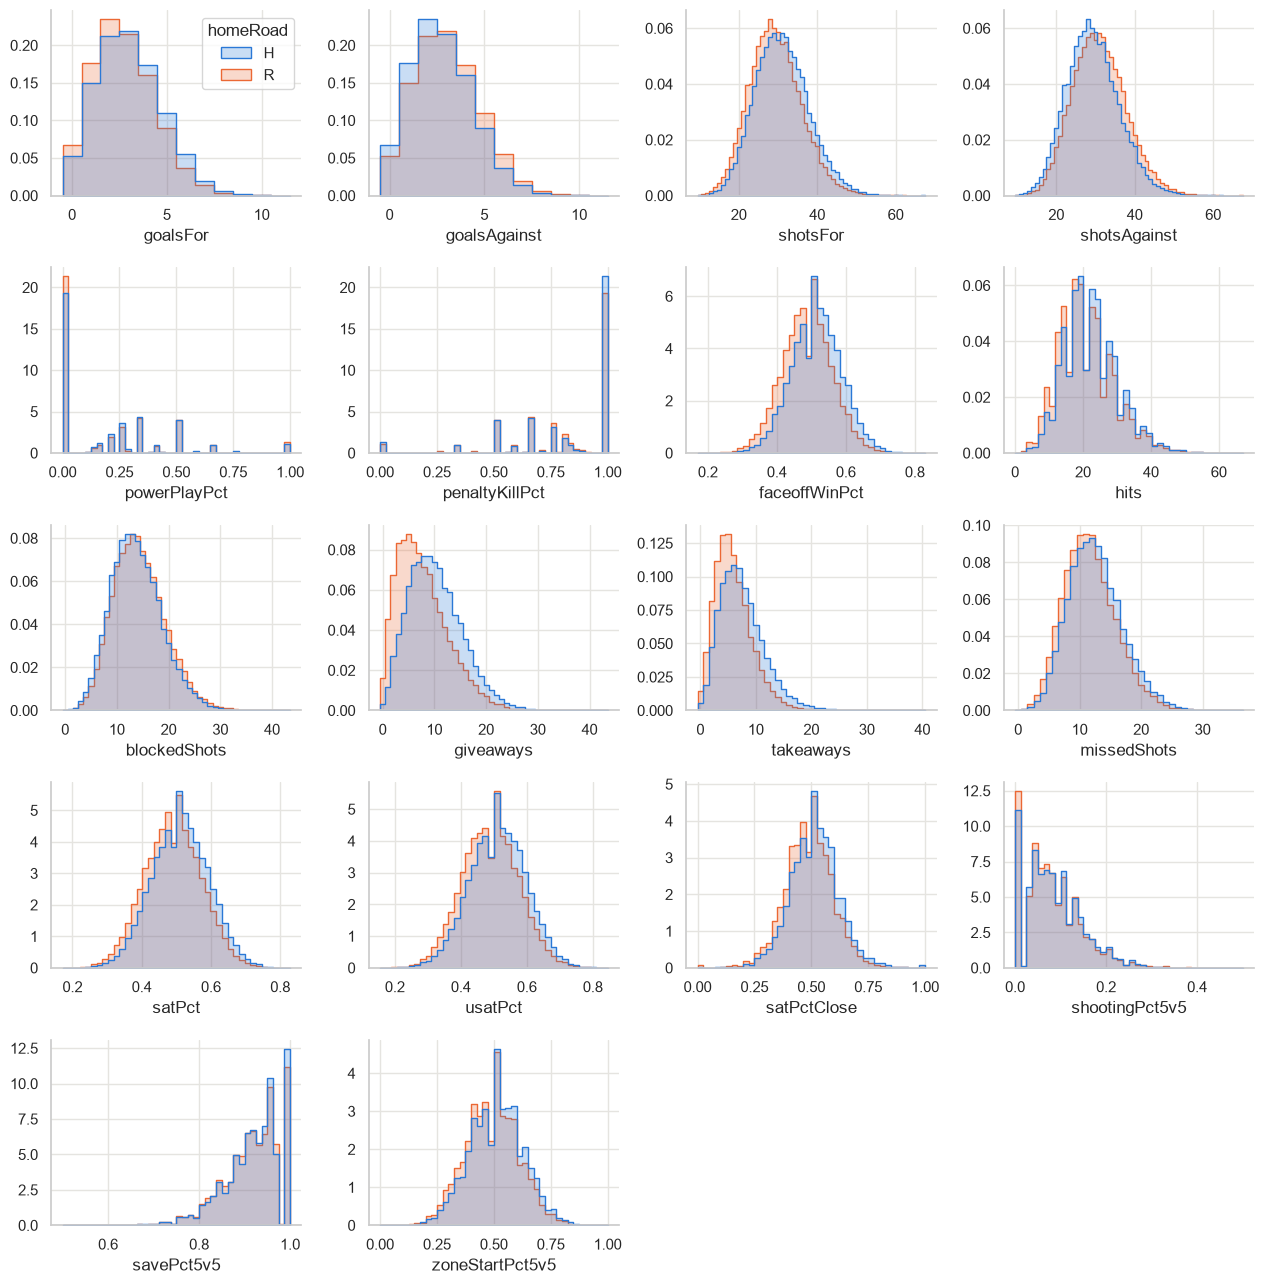

In [11]:
histos(teams, num_teams, hue="homeRoad")

Avantage local : écart moyen domicile − extérieur pour chaque variable, en unités d'écart-type
(effet standardisé). Utile pour décider si les variables doivent être exprimées relativement
au contexte (domicile/extérieur). Attention : les statistiques « subjectives » (mises en échec,
revirements) sont compilées par les marqueurs de l'aréna local, d'où une partie de l'écart.

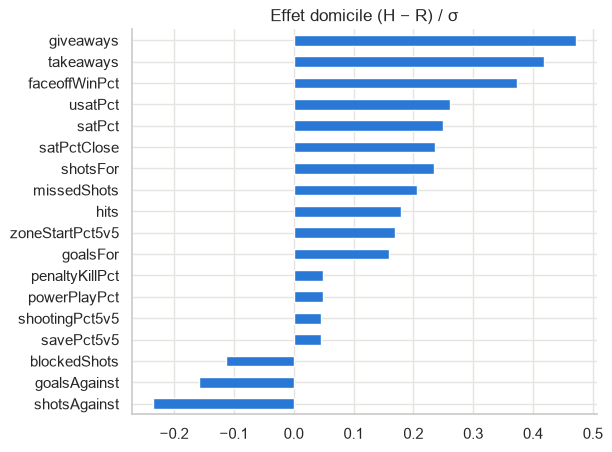

In [12]:
effet = (teams.groupby("homeRoad")[num_teams].mean().diff().iloc[-1] * -1) / teams[num_teams].std()
effet.sort_values().plot.barh(color=BLEU, figsize=(6, 5), title="Effet domicile (H − R) / σ");

,var_1,var_2,r
246,satPct,usatPct,0.913
289,goalsAgainst,savePct5v5,-0.764
270,goalsFor,shootingPct5v5,0.764
264,satPct,satPctClose,0.736


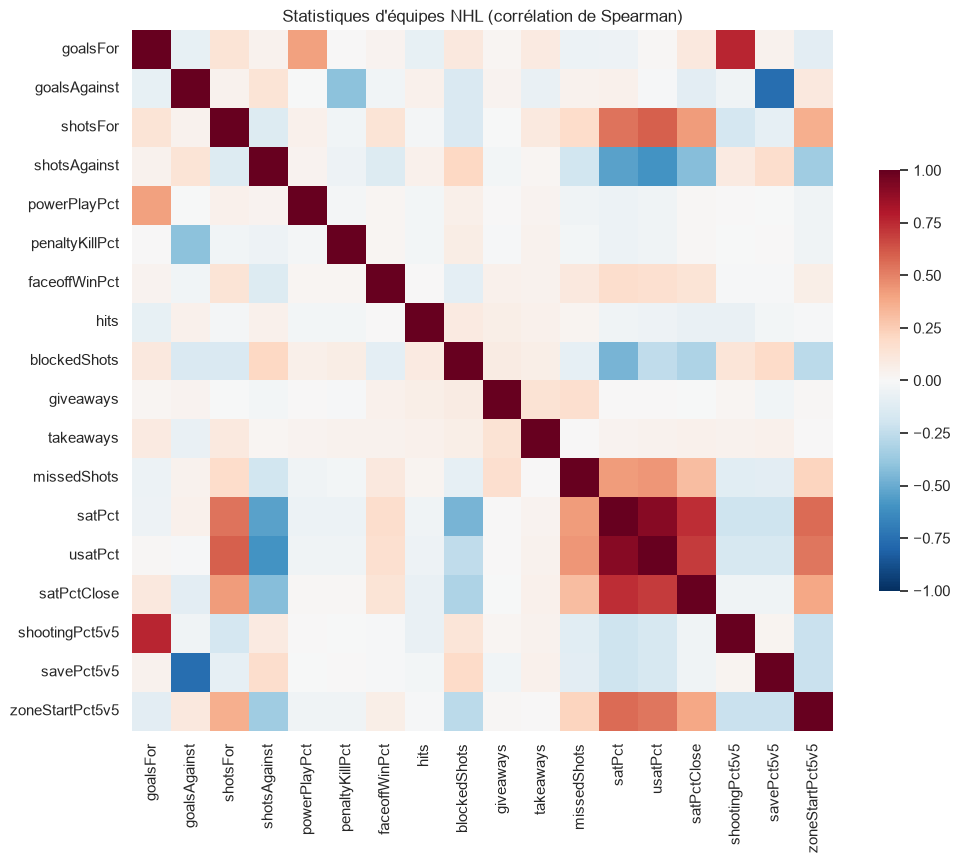

In [13]:
corr_teams = heatmap_corr(teams, num_teams, "Statistiques d'équipes NHL")
paires_correlees(corr_teams, 0.7)

### 1.4 Statistiques des patineurs — `summary` + `timeonice`

Une ligne par patineur-match. Points d'attention pour l'agrégation au niveau de l'équipe :
nombre de patineurs par équipe-match, distributions très asymétriques (beaucoup de zéros) et
temps de glace très différent entre attaquants et défenseurs.

In [14]:
skaters = sql(
    """
    SELECT s.gameId, s.playerId, s.teamAbbrev, s.positionCode, s.goals, s.assists, s.points,
           s.plusMinus, s.shots, s.penaltyMinutes, s.ppPoints,
           t.timeOnIce, t.evTimeOnIce, t.ppTimeOnIce, t.shTimeOnIce, t.shifts
    FROM summary s
    LEFT JOIN timeonice t ON t.gameId = s.gameId AND t.playerId = s.playerId
    WHERE s.gameId >= :first
    """,
    first=FIRST_GAME_ID,
)
skaters = ajouter_saison(skaters)
for c in ["timeOnIce", "evTimeOnIce", "ppTimeOnIce", "shTimeOnIce"]:
    skaters[c] = skaters[c] / 60  # secondes -> minutes
skaters["poste"] = np.where(skaters["positionCode"] == "D", "D", "F")
print(f"{len(skaters):,} lignes patineur-match, {skaters['playerId'].nunique():,} joueurs")
print(skaters["positionCode"].value_counts().to_dict())
manquants(skaters)

914,479 lignes patineur-match, 3,484 joueurs
{'D': 308401, 'C': 272839, 'L': 172476, 'R': 160763}


,manquants,proportion


In [15]:
par_equipe = pd.crosstab([skaters["gameId"], skaters["teamAbbrev"]], skaters["poste"])
print("Patineurs par équipe-match :")
display(par_equipe.apply(pd.Series.value_counts).fillna(0).astype(int).sort_index())

num_sk = [
    "goals",
    "assists",
    "points",
    "plusMinus",
    "shots",
    "penaltyMinutes",
    "timeOnIce",
    "ppTimeOnIce",
    "shTimeOnIce",
    "shifts",
]
zeros = (skaters[num_sk] == 0).mean().rename("proportion de zéros")
pd.concat([skaters[num_sk].describe().T, zeros], axis=1)

Patineurs par équipe-match :


poste,D,F
4,3,0
5,532,0
6,46304,0
7,3927,0
8,52,0
9,0,3
10,0,77
11,0,4058
12,0,46197
13,0,483


,count,mean,std,min,25%,50%,75%,max,proportion de zéros
goals,"914,479.000",0.160,0.415,0.000,0.000,0.000,0.000,5.000,0.857
assists,"914,479.000",0.271,0.543,0.000,0.000,0.000,0.000,6.000,0.771
points,"914,479.000",0.431,0.702,0.000,0.000,0.000,1.000,8.000,0.669
plusMinus,"914,479.000",-0.008,1.125,-7.000,-1.000,0.000,1.000,7.000,0.425
shots,"914,479.000",1.673,1.546,0.000,1.000,1.000,2.000,16.000,0.250
penaltyMinutes,"914,479.000",0.575,1.560,0.000,0.000,0.000,0.000,42.000,0.801
timeOnIce,"914,479.000",16.481,4.937,0.000,13.233,16.617,19.850,38.900,0.000
ppTimeOnIce,"914,479.000",1.557,1.863,0.000,0.000,0.883,2.617,20.083,0.323
shTimeOnIce,"914,479.000",1.237,1.501,0.000,0.000,0.700,2.067,13.383,0.360
shifts,"914,479.000",21.258,5.500,0.000,18.000,21.000,25.000,52.000,0.000


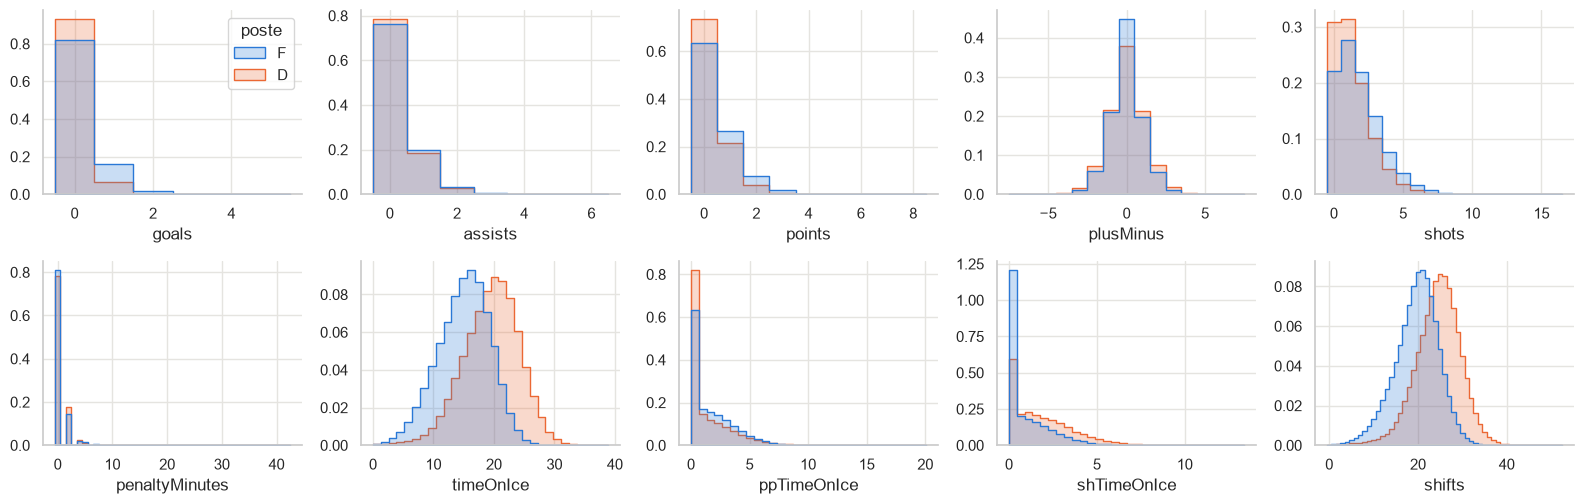

In [16]:
histos(skaters, num_sk, hue="poste", bins=30, ncols=5)

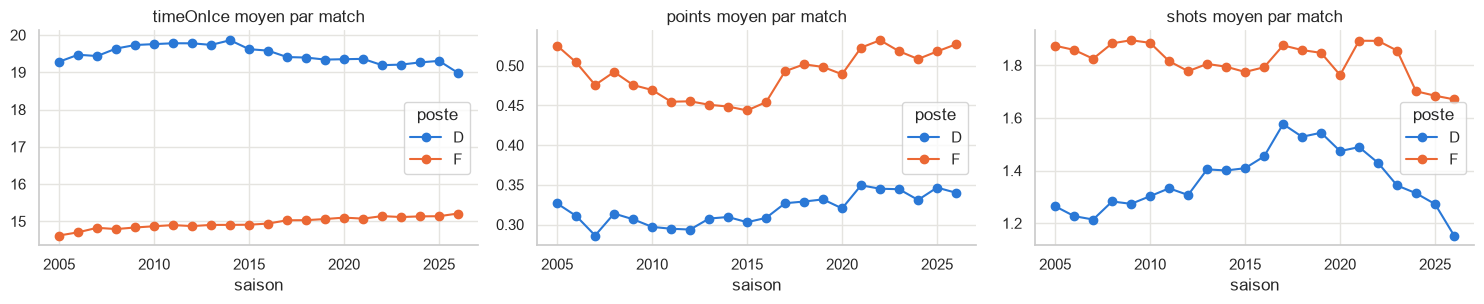

In [17]:
# Évolution du temps de glace et de la production par saison (changement de contexte de jeu)
evol = skaters.pivot_table(
    index="saison", columns="poste", values=["timeOnIce", "points", "shots"], aggfunc="mean"
)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, c in zip(axes, ["timeOnIce", "points", "shots"], strict=True):
    evol[c].plot(ax=ax, marker="o", color=[BLEU, ORANGE], title=f"{c} moyen par match")
fig.tight_layout()

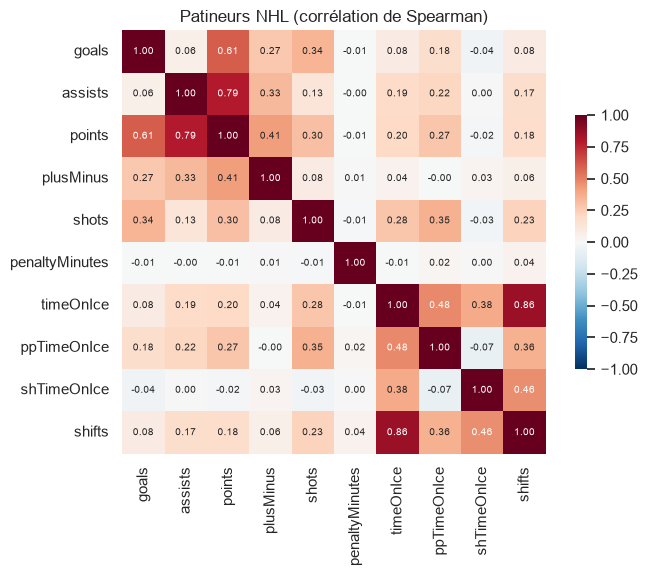

In [18]:
corr_sk = heatmap_corr(skaters, num_sk, "Patineurs NHL")

### 1.5 Statistiques des gardiens — `g_summary`

Une ligne par gardien ayant joué. Point clé pour la prédiction : il faut identifier le
**partant** (`gamesStarted`), car c'est lui qui est connu avant le match. Les relèves créent
des lignes avec peu de temps de glace et des taux (`savePct`) très instables.

In [19]:
goalies = sql(
    """
    SELECT gameId, playerId, teamAbbrev, homeRoad, gamesStarted, timeOnIce, shotsAgainst,
           saves, goalsAgainst, savePct, shutouts, wins, losses, otLosses
    FROM g_summary WHERE gameId >= :first
    """,
    first=FIRST_GAME_ID,
)
goalies = ajouter_saison(goalies)
goalies["timeOnIce"] = goalies["timeOnIce"] / 60
print(f"{len(goalies):,} lignes gardien-match, {goalies['playerId'].nunique():,} gardiens")
n = goalies.groupby(["gameId", "teamAbbrev"]).agg(
    gardiens=("playerId", "size"), partants=("gamesStarted", "sum")
)
print("gardiens par équipe-match :", n["gardiens"].value_counts().to_dict())
print("partants par équipe-match :", n["partants"].value_counts().to_dict())
manquants(goalies)

54,601 lignes gardien-match, 386 gardiens
gardiens par équipe-match : {1: 47037, 2: 3779, 3: 2}
partants par équipe-match : {1: 50818}


,manquants,proportion
savePct,84,0.002


gamesStarted               0          1
timeOnIce    count 3,783.000 50,818.000
             mean     29.308     58.157
             std      13.391      8.866
             min       0.000      0.517
             25%      19.942     59.000
             50%      29.467     60.000
             75%      39.558     60.000
             max      62.933     65.000
shotsAgainst count 3,783.000 50,818.000
             mean     12.970     29.020
             std       7.552      7.695
             min       0.000      0.000
             25%       7.000     24.000
             50%      12.000     29.000
             75%      18.000     34.000
             max      47.000     67.000
saves        count 3,783.000 50,818.000
             mean     11.642     26.375
             std       6.978      7.710
             min       0.000      0.000
             25%       6.000     22.000
             50%      11.000     26.000
             75%      16.000     31.000
             max      45.000     64.000
goalsAgainst count 3,783.000 50,818.000
             mean      1.328      2.647
             std       1.252      1.484
             min       0.000      0.000
             25%       0.000      2.000
             50%       1.000      3.000
             75%       2.000      4.000
             max       7.000     10.000
savePct      count 3,706.000 50,811.000
             mean      0.892      0.900
             std       0.111      0.076
             min       0.000      0.000
             25%       0.842      0.870
             50%       0.909      0.912
             75%       1.000      0.947
             max       1.000      1.000

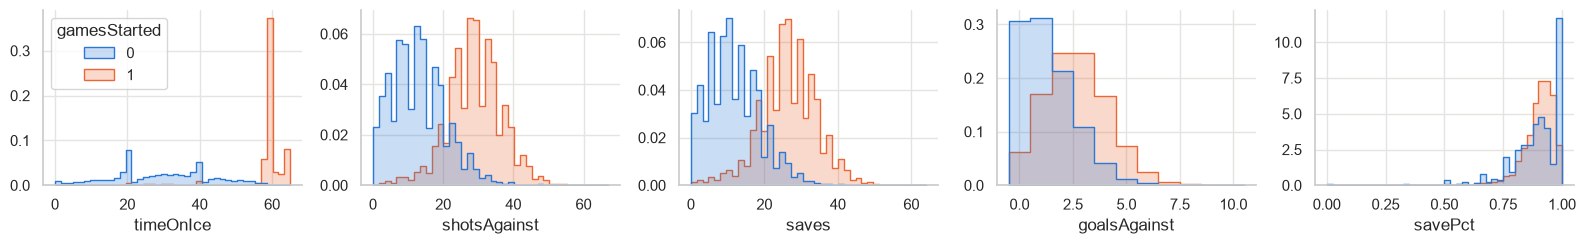

In [20]:
num_g = ["timeOnIce", "shotsAgainst", "saves", "goalsAgainst", "savePct"]
display(goalies.groupby("gamesStarted")[num_g].describe().T.round(3))
histos(goalies, num_g, hue="gamesStarted", ncols=5)

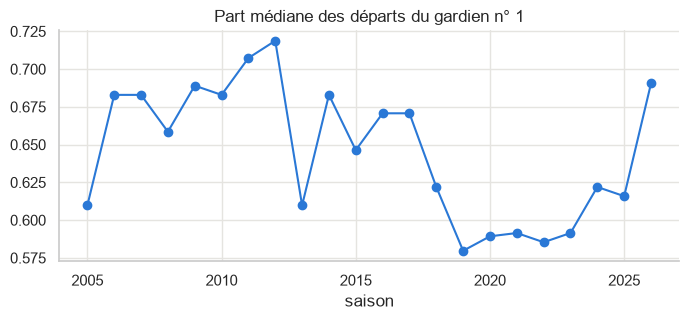

In [21]:
# Concentration des départs : part des matchs commencés par le gardien n° 1 de chaque équipe
dep = goalies[goalies["gamesStarted"] == 1]
part = (
    dep.groupby(["saison", "teamAbbrev", "playerId"])
    .size()
    .groupby(["saison", "teamAbbrev"])
    .agg(lambda s: s.max() / s.sum())
)
ax = part.groupby("saison").median().plot(marker="o", color=BLEU, figsize=(8, 3))
ax.set_title("Part médiane des départs du gardien n° 1");

## 2. MoneyPuck (CSV)

Fichiers *game by game* depuis 2008-2009, avec **une ligne par situation de jeu** (`all`,
`5on5`, `5on4`, `4on5`, `other`). Le fichier des patineurs fait ~2,5 Go : on ne lit que les
colonnes utiles (moteur `pyarrow`). Sauf mention contraire, l'analyse porte sur `all`.

In [22]:
mp_teams = pd.read_csv(MP_DIR / "teams" / "all_teams.csv", engine="pyarrow")
mp_teams = mp_teams[mp_teams["playoffGame"] == 0]  # séries incluses dans ce seul fichier
mp_goalies = pd.concat(
    [pd.read_csv(f, engine="pyarrow") for f in sorted((MP_DIR / "goalies").glob("*.csv"))],
    ignore_index=True,
)

SK_COLS = [
    "playerId",
    "gameId",
    "season",
    "playerTeam",
    "home_or_away",
    "position",
    "situation",
    "icetime",
    "shifts",
    "gameScore",
    "onIce_xGoalsPercentage",
    "onIce_corsiPercentage",
    "I_F_xGoals",
    "I_F_goals",
    "I_F_points",
    "I_F_shotsOnGoal",
    "I_F_shotAttempts",
    "I_F_hits",
    "I_F_takeaways",
    "I_F_giveaways",
    "OnIce_F_xGoals",
    "OnIce_A_xGoals",
]
mp_skaters = pd.concat(
    [
        pd.read_csv(f, engine="pyarrow", usecols=SK_COLS)
        for f in sorted((MP_DIR / "skaters").glob("*.csv"))
    ],
    ignore_index=True,
)

for name, df in [("équipes", mp_teams), ("patineurs", mp_skaters), ("gardiens", mp_goalies)]:
    cle = ["gameId", "playerId" if "playerId" in df else "playerTeam", "situation"]
    print(
        f"{name:10s} {df.shape[0]:>11,} lignes x {df.shape[1]:>3} col."
        f" | saisons {df['season'].min()}-{df['season'].max()}"
        f" | doublons (gameId, id, situation) : "
        f"{df.duplicated(cle).sum()}"
    )

équipes        217,440 lignes x 111 col. | saisons 2008-2026 | doublons (gameId, id, situation) : 0
patineurs    3,886,835 lignes x  22 col. | saisons 2008-2025 | doublons (gameId, id, situation) : 0
gardiens       231,540 lignes x  39 col. | saisons 2008-2025 | doublons (gameId, id, situation) : 0


In [23]:
# Répartition des lignes par situation et part de temps de glace (équipes)
sit = mp_teams.groupby("situation").agg(
    lignes=("gameId", "size"), temps_moyen_min=("iceTime", "mean")
)
sit["temps_moyen_min"] /= 60
sit

,lignes,temps_moyen_min
situation,,
4on5,43488,4.921
5on4,43488,4.921
5on5,43488,48.685
all,43488,60.808
other,43488,2.281


### 2.1 Matchs (reconstruits) et concordance avec la NHL

Table de matchs reconstruite à partir des lignes d'équipe locale en situation `all`. On compare
ensuite le nombre de matchs par saison et les scores avec la table `games` de la NHL.

In [24]:
mp_games = mp_teams.query("situation == 'all' and home_or_away == 'HOME'")[
    [
        "gameId",
        "season",
        "playoffGame",
        "playerTeam",
        "opposingTeam",
        "goalsFor",
        "goalsAgainst",
        "xGoalsFor",
        "xGoalsAgainst",
    ]
].rename(columns={"playerTeam": "home", "opposingTeam": "away"})
mp_games["home_win"] = (mp_games["goalsFor"] > mp_games["goalsAgainst"]).astype(int)
print(f"{len(mp_games):,} matchs, doublons : {mp_games['gameId'].duplicated().sum()}")

comp = mp_games.merge(
    games[["gameId", "score_home", "score_away"]], on="gameId", how="outer", indicator=True
)
comp["saison"] = comp["gameId"] // 1_000_000
display(pd.crosstab(comp["saison"], comp["_merge"]).query("index >= 2008"))
both = comp[comp["_merge"] == "both"]
print("buts locaux différents :", (both["goalsFor"] != both["score_home"]).sum())
print("buts visiteurs différents :", (both["goalsAgainst"] != both["score_away"]).sum())

21,638 matchs, doublons : 0


_merge,left_only,right_only,both
saison,,,
2008,0,3,1227
2009,0,1,1229
2010,0,0,1230
2011,0,41,1189
2012,0,24,696
2013,0,41,1189
2014,0,0,1230
2015,0,0,1230
2016,0,0,1230


buts locaux différents : 1055
buts visiteurs différents : 1085


Les buts MoneyPuck excluent le but « gagnant » de la fusillade, contrairement au score
officiel : les écarts se concentrent sur les matchs décidés en fusillade (vérification
ci-dessous). La cible doit donc venir de la table `games`. Quelques matchs NHL des saisons
2011-2013 sont absents de MoneyPuck (`right_only`).

In [25]:
diff = both[(both["goalsFor"] != both["score_home"]) | (both["goalsAgainst"] != both["score_away"])]
diff.merge(games[["gameId", "end_game_type"]], on="gameId")["end_game_type"].value_counts()

end_game_type
SO     2132
REG       6
Name: count, dtype: int64

### 2.2 Statistiques d'équipes

In [26]:
mp_t = mp_teams[mp_teams["situation"] == "all"].copy()
print(f"{len(mp_t):,} lignes équipe-match (situation all)")
display(manquants(mp_teams))

num_mp_t = [
    "xGoalsPercentage",
    "corsiPercentage",
    "fenwickPercentage",
    "xGoalsFor",
    "goalsFor",
    "shotsOnGoalFor",
    "shotAttemptsFor",
    "highDangerShotsFor",
    "highDangerxGoalsFor",
    "reboundsFor",
    "faceOffsWonFor",
    "hitsFor",
    "takeawaysFor",
    "giveawaysFor",
    "penaltiesFor",
    "scoreVenueAdjustedxGoalsFor",
]
mp_t[num_mp_t].describe().T

43,488 lignes équipe-match (situation all)


,manquants,proportion


,count,mean,std,min,25%,50%,75%,max
xGoalsPercentage,"43,488.000",0.500,0.117,0.084,0.418,0.500,0.582,0.916
corsiPercentage,"43,488.000",0.500,0.080,0.207,0.445,0.500,0.555,0.792
fenwickPercentage,"43,488.000",0.500,0.081,0.191,0.444,0.500,0.556,0.809
xGoalsFor,"43,488.000",2.864,0.969,0.323,2.173,2.754,3.444,11.565
goalsFor,"43,488.000",2.876,1.688,0.000,2.000,3.000,4.000,11.000
shotsOnGoalFor,"43,488.000",30.207,6.801,3.000,25.000,30.000,35.000,67.000
shotAttemptsFor,"43,488.000",56.878,11.401,9.000,49.000,56.000,64.000,116.000
highDangerShotsFor,"43,488.000",2.783,1.960,0.000,1.000,2.000,4.000,22.000
highDangerxGoalsFor,"43,488.000",0.976,0.767,0.000,0.426,0.829,1.374,10.718
reboundsFor,"43,488.000",2.406,1.874,0.000,1.000,2.000,3.000,16.000


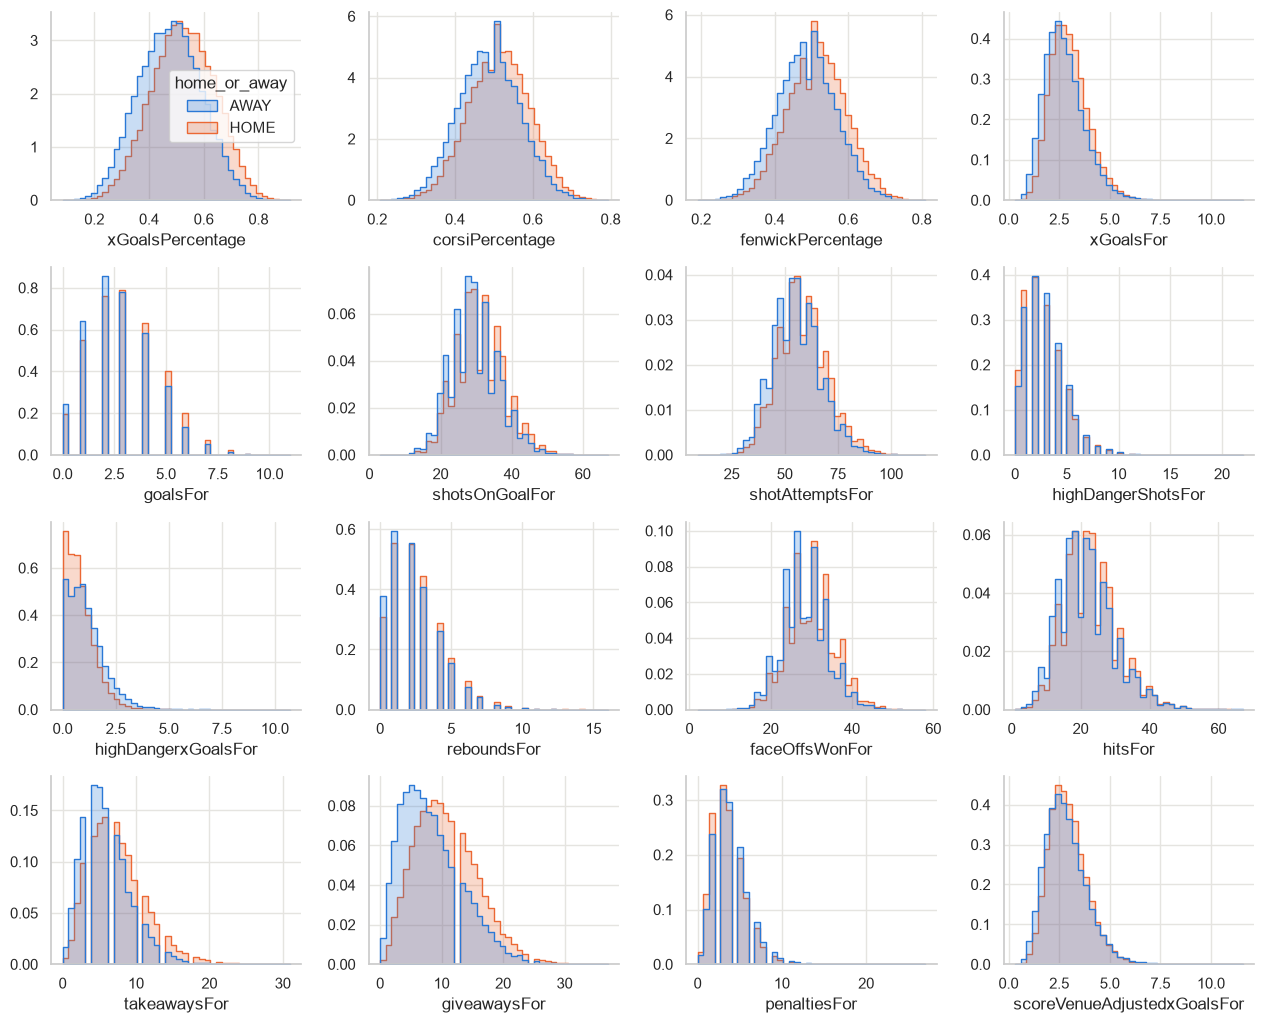

In [27]:
histos(mp_t, num_mp_t, hue="home_or_away")

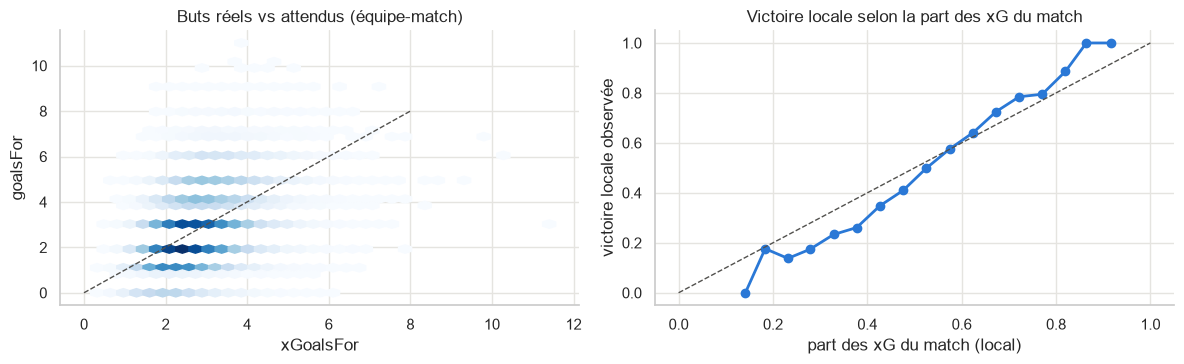

In [28]:
# Buts vs buts attendus : variance du résultat d'un match par rapport à sa « qualité »
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hexbin(mp_t["xGoalsFor"], mp_t["goalsFor"], gridsize=35, cmap="Blues", mincnt=1)
axes[0].plot([0, 8], [0, 8], color=GRIS, ls="--", lw=1)
axes[0].set(xlabel="xGoalsFor", ylabel="goalsFor", title="Buts réels vs attendus (équipe-match)")
mp_g = mp_games.assign(
    xg_pct=mp_games["xGoalsFor"] / (mp_games["xGoalsFor"] + mp_games["xGoalsAgainst"])
)
mp_g["bin"] = pd.cut(mp_g["xg_pct"], np.linspace(0, 1, 21))
cal = mp_g.groupby("bin", observed=True).agg(
    x=("xg_pct", "mean"), y=("home_win", "mean"), n=("gameId", "size")
)
axes[1].plot(cal["x"], cal["y"], marker="o", color=BLEU, lw=2)
axes[1].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
axes[1].set(
    xlabel="part des xG du match (local)",
    ylabel="victoire locale observée",
    title="Victoire locale selon la part des xG du match",
)
fig.tight_layout()

Le graphique de droite utilise des statistiques **du match lui-même** : il montre le lien entre
domination et résultat, pas une capacité prédictive (fuite d'information). Pour prédire, ces
variables devront être calculées sur les matchs **précédents** (moyennes mobiles, momentum).

,var_1,var_2,r
243,xGoalsFor,scoreVenueAdjustedxGoalsFor,0.992
135,highDangerShotsFor,highDangerxGoalsFor,0.926
33,corsiPercentage,fenwickPercentage,0.923


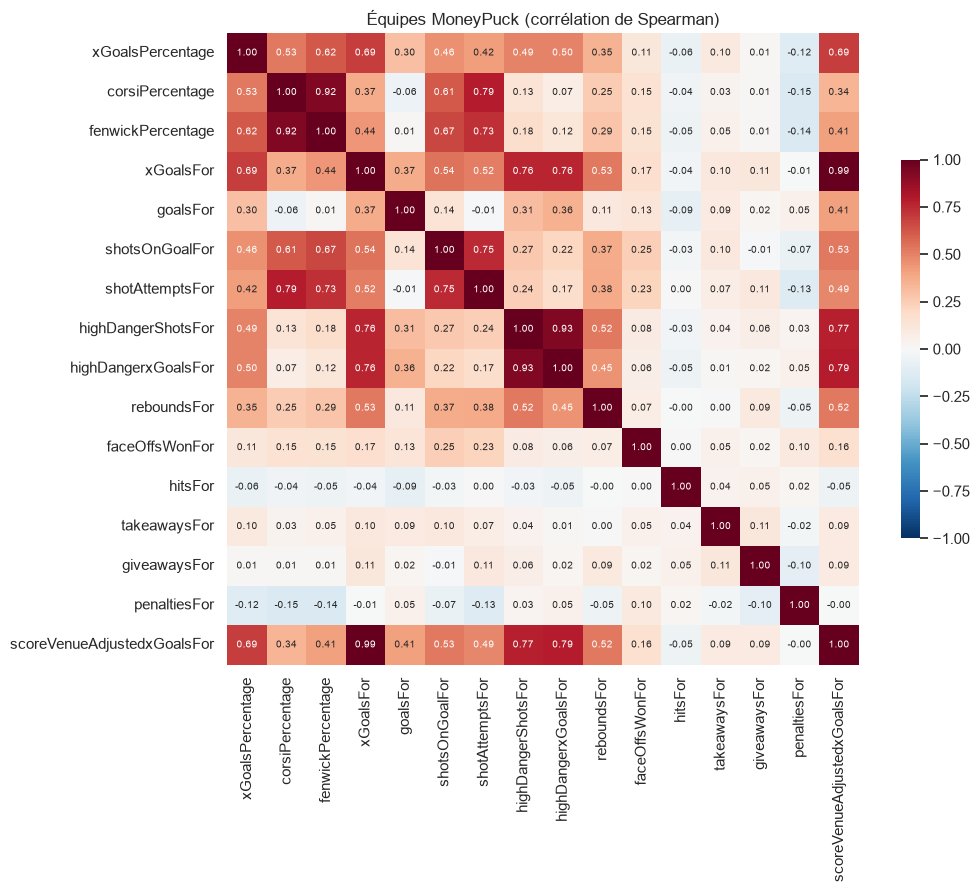

In [29]:
corr_mp_t = heatmap_corr(mp_t, num_mp_t, "Équipes MoneyPuck")
paires_correlees(corr_mp_t, 0.8)

101 variables ; composantes pour 80 / 90 / 95 % de variance : [17, 27, 35]


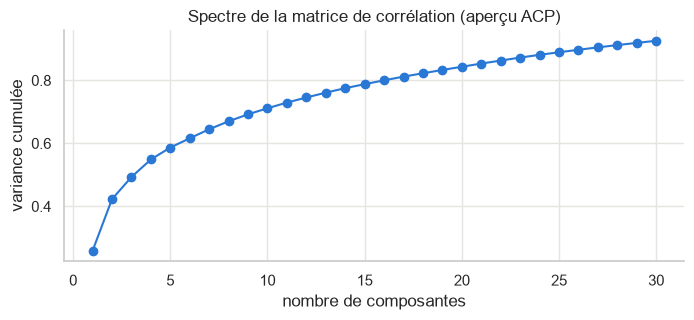

In [30]:
# Dimension : nombre de colonnes numériques et redondance globale (toutes variables, situation all)
X = mp_t.select_dtypes("number").drop(columns=["season", "gameId", "playoffGame"]).dropna(axis=1)
X = X.loc[:, X.std() > 0]
vp = np.linalg.eigvalsh(np.corrcoef(X.to_numpy(), rowvar=False))[::-1]
cum = np.cumsum(vp) / vp.sum()
print(
    f"{X.shape[1]} variables ; composantes pour 80 / 90 / 95 % de variance :",
    [int(np.searchsorted(cum, q) + 1) for q in (0.8, 0.9, 0.95)],
)
ax = pd.Series(cum[:30], index=range(1, 31)).plot(marker="o", color=BLEU, figsize=(8, 3))
ax.set(
    xlabel="nombre de composantes",
    ylabel="variance cumulée",
    title="Spectre de la matrice de corrélation (aperçu ACP)",
);

### 2.3 Statistiques des patineurs

In [31]:
mp_s = mp_skaters[mp_skaters["situation"] == "all"].copy()
mp_s["icetime"] = mp_s["icetime"] / 60
mp_s["poste"] = np.where(mp_s["position"] == "D", "D", "F")
print(
    f"{len(mp_s):,} lignes patineur-match (situation all), {mp_s['playerId'].nunique():,} joueurs"
)
display(manquants(mp_skaters))
print(
    "Patineurs par équipe-match :",
    mp_s.groupby(["gameId", "playerTeam"]).size().value_counts().head(6).to_dict(),
)

num_mp_s = [
    "icetime",
    "shifts",
    "gameScore",
    "onIce_xGoalsPercentage",
    "onIce_corsiPercentage",
    "I_F_xGoals",
    "I_F_goals",
    "I_F_points",
    "I_F_shotsOnGoal",
    "I_F_hits",
    "I_F_takeaways",
    "I_F_giveaways",
]
zeros = (mp_s[num_mp_s] == 0).mean().rename("proportion de zéros")
pd.concat([mp_s[num_mp_s].describe().T, zeros], axis=1)

777,367 lignes patineur-match (situation all), 3,059 joueurs


,manquants,proportion


Patineurs par équipe-match : {18: 43025, 17: 146, 16: 13, 19: 5, 15: 4, 13: 4}


,count,mean,std,min,25%,50%,75%,max,proportion de zéros
icetime,"777,367.000",16.506,4.831,0.017,13.300,16.600,19.800,38.900,0.000
shifts,"777,367.000",21.256,5.347,1.000,18.000,21.000,25.000,46.000,0.000
gameScore,"777,367.000",0.454,0.742,-2.500,-0.060,0.300,0.850,7.110,0.015
onIce_xGoalsPercentage,"777,367.000",0.498,0.211,0.000,0.342,0.501,0.657,1.000,0.004
onIce_corsiPercentage,"777,367.000",0.501,0.144,0.000,0.405,0.500,0.600,1.000,0.002
I_F_xGoals,"777,367.000",0.159,0.217,0.000,0.018,0.078,0.212,4.217,0.155
I_F_goals,"777,367.000",0.160,0.415,0.000,0.000,0.000,0.000,5.000,0.857
I_F_points,"777,367.000",0.430,0.699,0.000,0.000,0.000,1.000,8.000,0.669
I_F_shotsOnGoal,"777,367.000",1.680,1.541,0.000,1.000,1.000,2.000,15.000,0.246
I_F_hits,"777,367.000",1.244,1.424,0.000,0.000,1.000,2.000,16.000,0.383


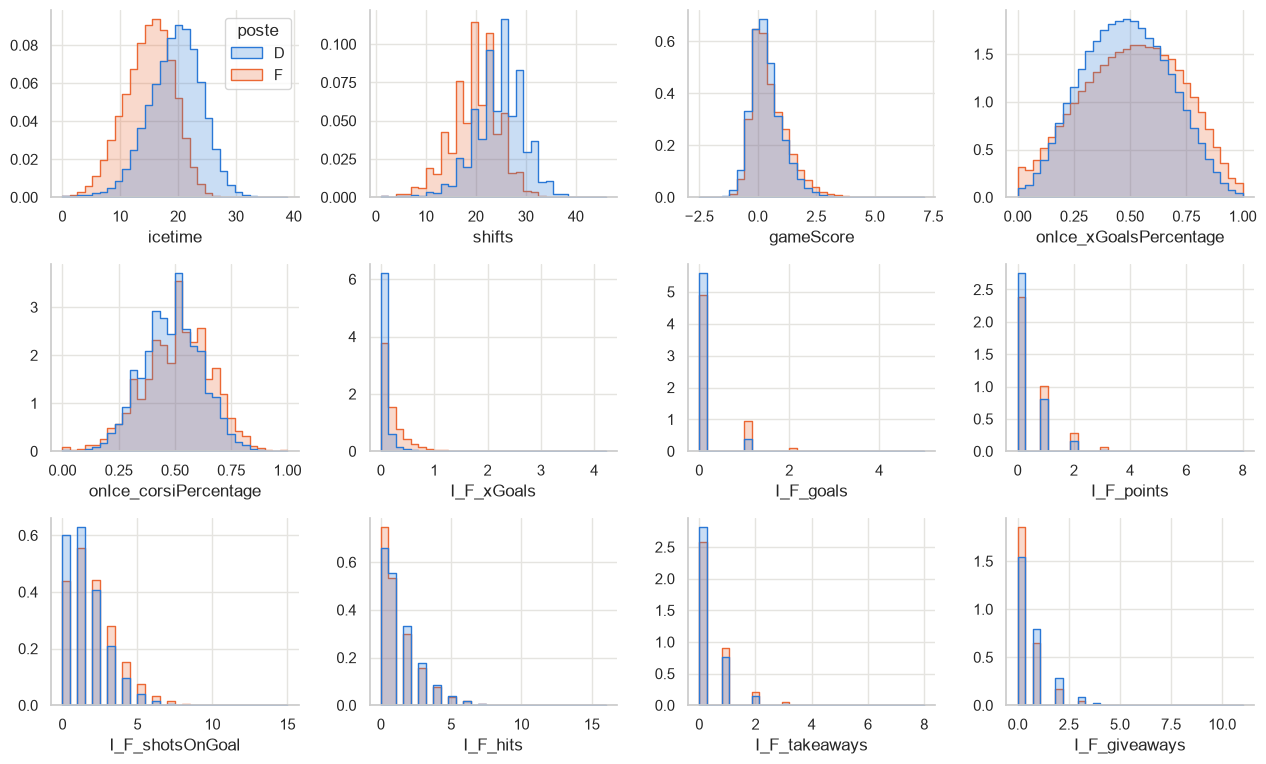

In [32]:
histos(mp_s, num_mp_s, hue="poste", bins=30)

Les pourcentages sur la glace (`onIce_*Percentage`) sont beaucoup plus dispersés (souvent 0 ou
1) pour les joueurs avec peu de temps de glace : leur agrégation au niveau de l'équipe devrait
être pondérée par le temps de glace plutôt qu'une simple moyenne.

In [33]:
mp_s["tranche_tg"] = pd.cut(mp_s["icetime"], [0, 5, 10, 15, 20, 25, 60])
mp_s.groupby("tranche_tg", observed=True).agg(
    lignes=("playerId", "size"),
    xg_pct_extreme=("onIce_xGoalsPercentage", lambda s: s.isin([0, 1]).mean()),
    xg_pct_ecart_type=("onIce_xGoalsPercentage", "std"),
)

,lignes,xg_pct_extreme,xg_pct_ecart_type
tranche_tg,,,
"(0, 5]",7570,0.311,0.352
"(5, 10]",65957,0.029,0.261
"(10, 15]",213870,0.002,0.222
"(15, 20]",306550,0.000,0.199
"(20, 25]",155137,0.000,0.183
"(25, 60]",28283,0.000,0.169


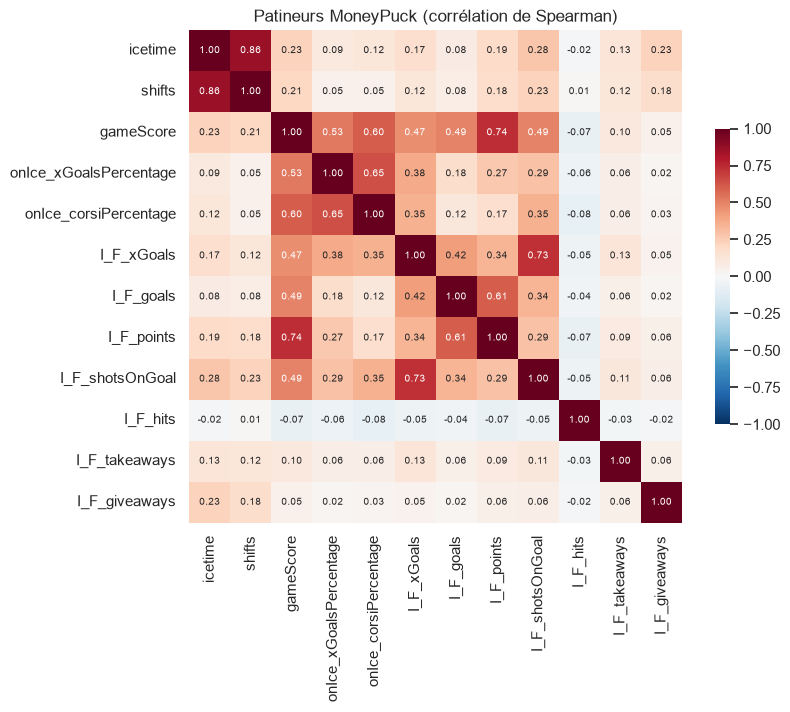

In [34]:
corr_mp_s = heatmap_corr(mp_s, num_mp_s, "Patineurs MoneyPuck")

### 2.4 Statistiques des gardiens

MoneyPuck n'indique pas le partant ; on le déduit (gardien avec le plus de temps de glace pour
l'équipe dans le match). Mesure clé : **GSAx** = `xGoals − goals` (buts sauvés au-delà des
attentes).

In [35]:
mp_gk = mp_goalies[mp_goalies["situation"] == "all"].copy()
mp_gk["icetime"] = mp_gk["icetime"] / 60
mp_gk["GSAx"] = mp_gk["xGoals"] - mp_gk["goals"]
mp_gk["save_pct"] = 1 - mp_gk["goals"] / mp_gk["ongoal"]
rang = mp_gk.groupby(["gameId", "playerTeam"])["icetime"].rank(ascending=False, method="first")
mp_gk["partant"] = (rang == 1).astype(int)
print(f"{len(mp_gk):,} lignes gardien-match, {mp_gk['playerId'].nunique():,} gardiens")
print(
    "gardiens par équipe-match :",
    mp_gk.groupby(["gameId", "playerTeam"]).size().value_counts().to_dict(),
)
display(manquants(mp_goalies))

num_mp_g = [
    "icetime",
    "ongoal",
    "goals",
    "xGoals",
    "GSAx",
    "save_pct",
    "highDangerShots",
    "highDangerGoals",
    "rebounds",
    "xRebounds",
]
mp_gk.groupby("partant")[num_mp_g].mean().T

46,308 lignes gardien-match, 341 gardiens
gardiens par équipe-match : {1: 40089, 2: 3108, 3: 1}


,manquants,proportion


partant,0,1
icetime,18.668,58.869
ongoal,9.752,29.387
goals,1.906,2.601
xGoals,0.952,2.658
GSAx,-0.954,0.057
save_pct,0.798,0.907
highDangerShots,0.976,2.496
highDangerGoals,0.498,0.761
rebounds,0.816,2.338
xRebounds,0.658,2.038


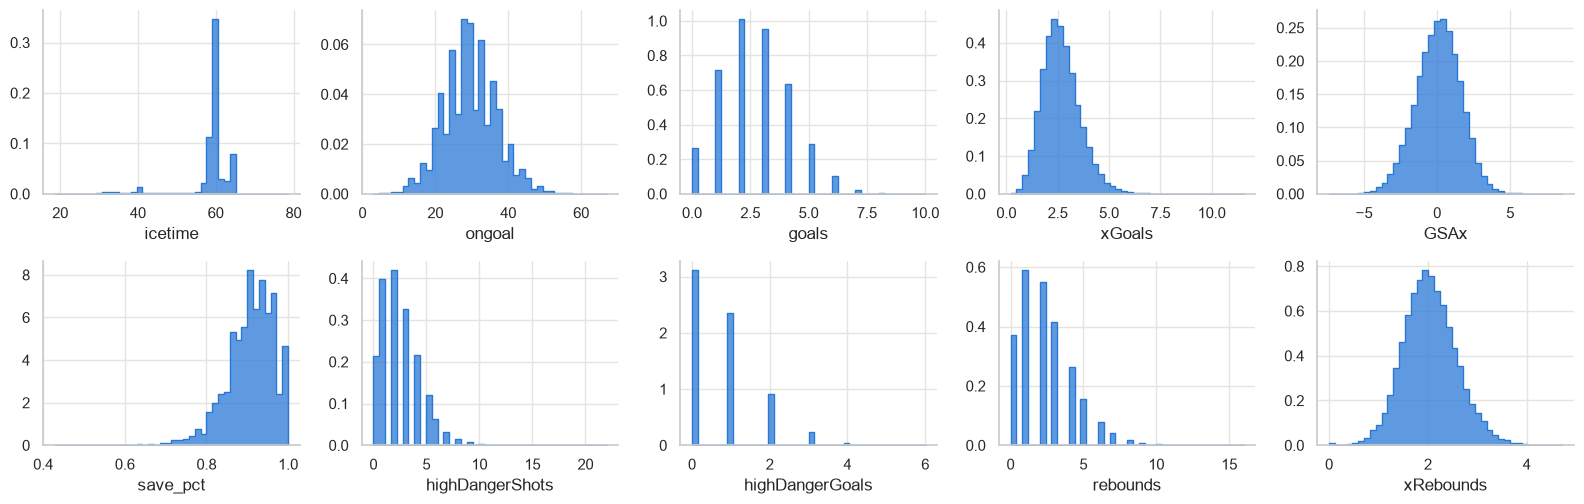

In [36]:
histos(mp_gk[mp_gk["partant"] == 1], num_mp_g, ncols=5)

In [37]:
# Stabilité du GSAx : corrélation entre la moyenne d'un gardien sur deux moitiés de saison
p = mp_gk[(mp_gk["partant"] == 1)].sort_values("gameId")
p["moitie"] = p.groupby(["season", "playerId"]).cumcount() % 2
m = p.groupby(["season", "playerId", "moitie"], as_index=False).agg(
    gsax=("GSAx", "mean"), n=("GSAx", "size")
)
m = (
    m[m["n"] >= 15]
    .pivot_table(index=["season", "playerId"], columns="moitie", values="gsax")
    .dropna()
)
print(f"{len(m)} gardiens-saisons ; corrélation pair/impair du GSAx moyen : {m[0].corr(m[1]):.2f}")

666 gardiens-saisons ; corrélation pair/impair du GSAx moyen : 0.15
